In [8]:
#pip install numpy matplotlib scipy opencv-python

Por favor, ingresa los 768 números térmicos separados por comas o espacios: 25.3,25.5,26.0,25.9,27.1,27.1,27.6,27.1,27.3,26.7,26.9,26.8,26.7,26.3,26.4,26.2,26.4,26.2,26.6,26.4,26.8,26.7,27.1,26.8,27.3,27.2,27.3,27.1,26.6,25.9,24.4,23.5 25.3,26.0,25.7,25.7,25.7,26.3,26.4,26.5,26.0,26.0,25.5,25.8,25.3,25.4,25.2,25.3,25.2,25.2,25.2,25.5,25.5,25.9,25.9,26.4,26.3,26.6,26.2,26.3,25.2,24.9,23.4,24.0 25.5,25.4,25.5,25.0,25.3,24.9,25.3,25.0,25.2,24.8,25.2,25.0,25.2,25.0,25.1,24.9,25.2,24.8,24.9,24.7,24.6,24.5,24.6,24.7,25.0,24.5,24.4,24.1,24.4,23.9,24.2,23.6 25.5,25.5,25.0,25.2,25.0,25.2,25.0,25.2,24.9,25.3,25.1,25.2,25.0,25.2,25.1,25.3,24.9,25.2,24.8,25.0,24.5,24.6,24.3,24.5,24.2,24.2,24.0,24.4,24.1,24.3,23.6,24.1 24.9,24.8,25.2,25.0,25.3,25.0,25.5,25.2,25.4,25.3,25.5,25.4,25.5,25.3,25.5,25.3,25.4,25.1,25.2,24.9,24.7,24.4,24.5,24.3,24.2,24.2,24.3,24.1,24.4,24.1,24.3,24.2 24.9,25.0,24.9,25.2,25.1,25.3,25.3,25.4,25.2,25.3,25.3,25.5,25.4,25.4,25.3,25.5,25.2,25.2,24.9,25.0,24.3,24.5,24.2,24.4,24.2

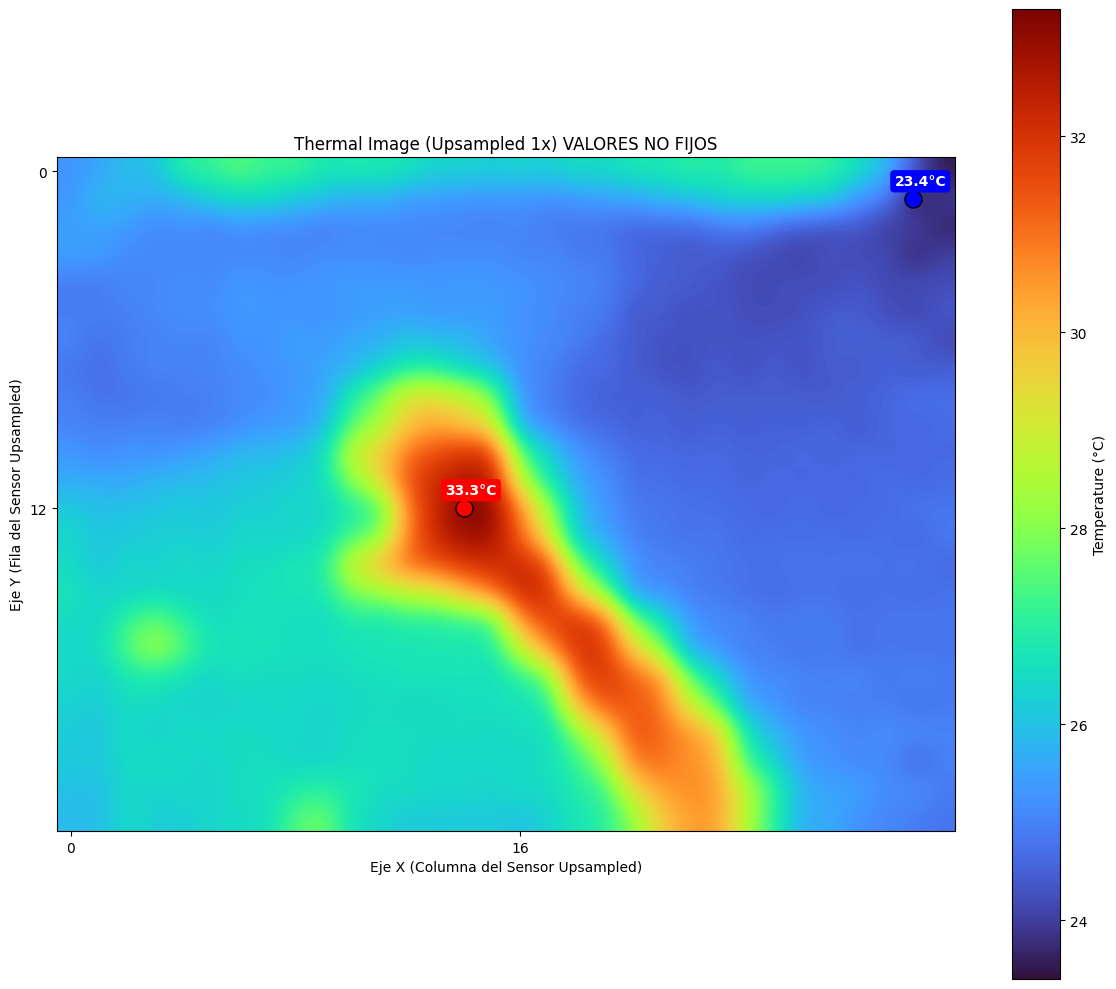


✓ Imagen RGB cargada: /content/rgb_image.jpg (960×1280 px)
✓ Homografía cargada desde 'homografia.npy'

✓ Resultado guardado como 'fusion_resultado.png'


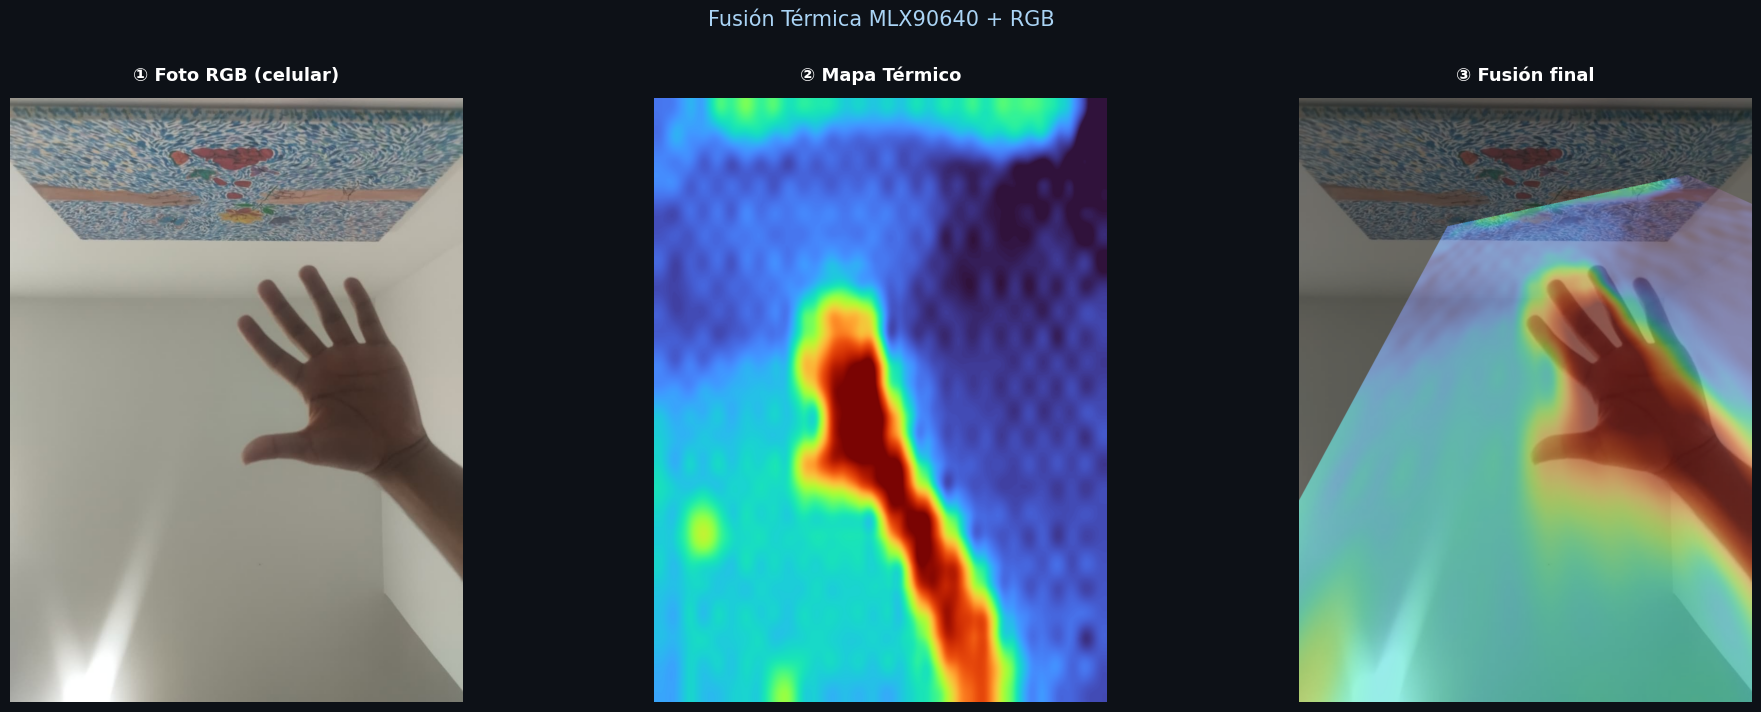

In [13]:
# -*- coding: utf-8 -*-
"""
╔══════════════════════════════════════════════════════════════════╗
║         FUSIÓN TÉRMICA MLX90640 + IMAGEN RGB DE CELULAR          ║
║                         versión 2.0                              ║
╚══════════════════════════════════════════════════════════════════╝

MODOS DISPONIBLES (cambia la variable MODO al inicio):
  "solo_termica"  → genera exactamente la misma imagen que el código original
  "calibrar"      → marca puntos de referencia y guarda la homografía
  "fusionar"      → superpone el mapa térmico sobre la foto RGB
"""

# ╔══════════════════════════════════════════════════════╗
# ║              PARÁMETROS — MODIFICA AQUÍ              ║
# ╚══════════════════════════════════════════════════════╝

MODO = "fusionar"
# Opciones: "solo_termica" | "calibrar" | "fusionar"

RUTA_IMAGEN_RGB = "/content/rgb_image.jpg"
# Nombre de tu foto RGB (debe estar en la misma carpeta que este script)

HOMOGRAFIA_PATH = "homografia.npy"
# Archivo donde se guarda/carga la homografía

ALPHA_TERMICO = 0.45
# Opacidad del mapa térmico sobre la foto (0.0 = solo RGB, 1.0 = solo térmico)

# ╚══════════════════════════════════════════════════════╝


# ─────────────────────────────────────────────────────────────────
# TU CÓDIGO ORIGINAL — sin ningún cambio
# ─────────────────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt

# Define camera resolution
resolution_x = 32
resolution_y = 24

# The total number of thermal readings
total_readings = resolution_x * resolution_y

thermal_input_string = input(f"Por favor, ingresa los {total_readings} números térmicos separados por comas o espacios: ")

try:
    processed_input = thermal_input_string.replace(',', ' ')
    thermal_numbers_list = [float(num) for num in processed_input.split() if num]
except ValueError:
    raise ValueError("Error al convertir los datos. Asegúrate de que todos los valores sean números válidos separados por comas o espacios.")

simulated_thermal_numbers = np.array(thermal_numbers_list)

if len(simulated_thermal_numbers) != total_readings:
    raise ValueError(f"Se esperaban {total_readings} lecturas térmicas, pero se recibieron {len(simulated_thermal_numbers)}.")

print(f"Cargadas {len(simulated_thermal_numbers)} lecturas térmicas.")

thermal_image_data = simulated_thermal_numbers.reshape(resolution_y, resolution_x)

print(f"Reshaped data into a {thermal_image_data.shape} array.")

from scipy.ndimage import gaussian_filter

sigma = 3.0
smoothed_thermal_image_data = gaussian_filter(thermal_image_data, sigma=sigma)

print(f"Data smoothed with a Gaussian filter (sigma={sigma}).")

from scipy.ndimage import zoom
import os

zoom_factor = 1

print(f"Procesando imagen térmica con:\n- Zoom factor: {zoom_factor}")

new_resolution_y = thermal_image_data.shape[0] * zoom_factor
new_resolution_x = thermal_image_data.shape[1] * zoom_factor

print(f"Dimensiones originales: {thermal_image_data.shape}")
print(f"Nuevas dimensiones después del zoom: ({new_resolution_y}, {new_resolution_x})")

upsampled_thermal_data = zoom(thermal_image_data, zoom=zoom_factor, order=1)

max_temp_upsampled = np.max(upsampled_thermal_data)
min_temp_upsampled = np.min(upsampled_thermal_data)
max_loc_upsampled = np.unravel_index(np.argmax(upsampled_thermal_data), upsampled_thermal_data.shape)
min_loc_upsampled = np.unravel_index(np.argmin(upsampled_thermal_data), upsampled_thermal_data.shape)

avg_temp_upsampled = np.mean(upsampled_thermal_data)
temp_range_upsampled = max_temp_upsampled - min_temp_upsampled

# ── Imagen térmica: EXACTAMENTE igual a tu código original ──
plt.figure(figsize=(12, 10))
plt.imshow(upsampled_thermal_data, cmap="turbo", interpolation='bicubic')
plt.colorbar(label='Temperature (°C)')
plt.title(f'Thermal Image (Upsampled {zoom_factor}x) VALORES NO FIJOS')
plt.xlabel('Eje X (Columna del Sensor Upsampled)')
plt.ylabel('Eje Y (Fila del Sensor Upsampled)')
plt.xticks(np.arange(0, new_resolution_x, resolution_x // 2))
plt.yticks(np.arange(0, new_resolution_y, resolution_y // 2))
plt.scatter(max_loc_upsampled[1], max_loc_upsampled[0], marker='o', color='red', s=150, edgecolors='black', linewidth=1, label=f'Max: {max_temp_upsampled:.1f}°C')
plt.scatter(min_loc_upsampled[1], min_loc_upsampled[0], marker='o', color='blue', s=150, edgecolors='black', linewidth=1, label=f'Min: {min_temp_upsampled:.1f}°C')
plt.annotate(f'{max_temp_upsampled:.1f}°C', (max_loc_upsampled[1], max_loc_upsampled[0]), textcoords="offset points", xytext=(5,10), ha='center', color='white', fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="red", ec="none", lw=0))
plt.annotate(f'{min_temp_upsampled:.1f}°C', (min_loc_upsampled[1], min_loc_upsampled[0]), textcoords="offset points", xytext=(5,10), ha='center', color='white', fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="blue", ec="none", lw=0))
plt.tight_layout()

if MODO == "solo_termica":
    plt.show()

# ─────────────────────────────────────────────────────────────────
# CÓDIGO NUEVO — solo se ejecuta si MODO es "calibrar" o "fusionar"
# ─────────────────────────────────────────────────────────────────

if MODO in ("calibrar", "fusionar"):

    import cv2

    # Guardar la figura térmica como imagen temporal para usarla en la fusión
    plt.savefig("_termica_temp.png", dpi=150, bbox_inches='tight')
    plt.show()

    # ── Cargar imagen RGB ──
    if not os.path.exists(RUTA_IMAGEN_RGB):
        raise FileNotFoundError(
            f"\nNo se encontró '{RUTA_IMAGEN_RGB}'.\n"
            f"Asegúrate de que la foto esté en la misma carpeta que este script\n"
            f"y que RUTA_IMAGEN_RGB tenga el nombre exacto del archivo."
        )

    rgb_bgr = cv2.imread(RUTA_IMAGEN_RGB)
    rgb     = cv2.cvtColor(rgb_bgr, cv2.COLOR_BGR2RGB)
    alto, ancho = rgb.shape[:2]
    print(f"\n✓ Imagen RGB cargada: {RUTA_IMAGEN_RGB} ({ancho}×{alto} px)")

    # ── Preparar imagen térmica en color para la fusión ──
    # Escalar la matriz térmica al tamaño de la imagen RGB con bicúbica
    termica_scaled = cv2.resize(
        upsampled_thermal_data.astype(np.float32),
        (ancho, alto),
        interpolation=cv2.INTER_CUBIC
    )
    # Normalizar percentiles 2-98
    p2, p98 = np.percentile(termica_scaled, 2), np.percentile(termica_scaled, 98)
    termica_norm  = np.clip((termica_scaled - p2) / (p98 - p2), 0, 1)
    termica_uint8 = (termica_norm * 255).astype(np.uint8)
    # Mismo colormap turbo convertido a BGR para OpenCV
    termica_bgr   = cv2.applyColorMap(termica_uint8, cv2.COLORMAP_TURBO)

    # ── CALIBRACIÓN ──
    if MODO == "calibrar":

        def mostrar_imagen_con_cuadricula(imagen, titulo, color_titulo):
            """Muestra la imagen con ejes y cuadrícula para leer coordenadas."""
            fig, ax = plt.subplots(figsize=(12, 9))
            ax.imshow(imagen)
            ax.set_title(titulo, color=color_titulo, fontsize=12, fontweight='bold', pad=12)
            # Cuadrícula cada 50 píxeles para facilitar la lectura
            h, w = imagen.shape[:2]
            ax.set_xticks(np.arange(0, w, 50))
            ax.set_yticks(np.arange(0, h, 50))
            ax.grid(color='white', linewidth=0.4, alpha=0.5)
            ax.tick_params(labelsize=8)
            plt.tight_layout()
            plt.show()
            print(f"  Tamaño de la imagen: {w} × {h} píxeles")

        def pedir_puntos(nombre_imagen):
            """
            Pide al usuario que ingrese coordenadas X,Y una por línea.
            Formato: X,Y  (ejemplo: 320,180)
            Escribe 'fin' cuando termines.
            """
            print(f"\nIngresa las coordenadas de los puntos en la imagen {nombre_imagen}.")
            print("Formato: X,Y  — ejemplo: 320,180")
            print("Escribe cada par en una línea y presiona Enter.")
            print("Cuando termines escribe 'fin' y presiona Enter.\n")
            puntos = []
            while True:
                linea = input(f"  Punto {len(puntos)+1} (o 'fin'): ").strip()
                if linea.lower() == 'fin':
                    break
                try:
                    partes = linea.replace(' ', '').split(',')
                    x, y = float(partes[0]), float(partes[1])
                    puntos.append((x, y))
                    print(f"    ✓ Punto {len(puntos)} registrado: ({x}, {y})")
                except Exception:
                    print("    ✗ Formato incorrecto. Escribe X,Y — ejemplo: 320,180")
            return puntos

        def mostrar_confirmacion(imagen, puntos, nombre, color):
            """Dibuja los puntos ingresados sobre la imagen para verificar."""
            fig, ax = plt.subplots(figsize=(12, 9))
            ax.imshow(imagen)
            for i, (x, y) in enumerate(puntos):
                ax.plot(x, y, 'o', color=color, markersize=10, markeredgecolor='black')
                ax.annotate(str(i+1), (x, y), textcoords="offset points", xytext=(8, 8),
                            color='white', fontsize=11, fontweight='bold',
                            bbox=dict(boxstyle="round,pad=0.2", fc=color, ec="none"))
            ax.set_title(f"Confirmación {nombre} — {len(puntos)} puntos marcados\n"
                         f"Verifica que estén bien ubicados",
                         color=color, fontsize=12)
            ax.axis('off')
            plt.tight_layout()
            plt.show()

        print("""
╔══════════════════════════════════════════════════════════════╗
║                    MODO CALIBRACIÓN                          ║
╠══════════════════════════════════════════════════════════════╣
║  PASOS:                                                      ║
║  1. Se muestra la imagen TÉRMICA con cuadrícula              ║
║  2. Mira la imagen, identifica los puntos de referencia      ║
║     y anota sus coordenadas X,Y mirando los ejes             ║
║  3. Ingresas las coordenadas en el input                     ║
║  4. Se repite con la imagen RGB                              ║
║  5. Se guarda homografia.npy                                 ║
╠══════════════════════════════════════════════════════════════╣
║  PUNTOS RECOMENDADOS (para una mano):                        ║
║   1. Punta pulgar       5. Punta meñique                     ║
║   2. Punta índice       6. Base del pulgar                   ║
║   3. Punta medio        7. Centro muñeca                     ║
║   4. Punta anular                                            ║
╚══════════════════════════════════════════════════════════════╝
""")

        # ── PASO 1: imagen TÉRMICA ──
        print("=" * 60)
        print("PASO 1/4 — Mostrando imagen TÉRMICA con cuadrícula...")
        print("Mira la imagen, identifica los puntos y anota X,Y de cada uno.")
        print("=" * 60)
        termica_vis = cv2.cvtColor(termica_bgr, cv2.COLOR_BGR2RGB)
        mostrar_imagen_con_cuadricula(
            termica_vis,
            "IMAGEN TÉRMICA — Identifica los puntos y anota sus coordenadas X,Y",
            "darkred"
        )

        # ── PASO 2: ingresar coordenadas de la térmica ──
        print("=" * 60)
        print("PASO 2/4 — Ingresa las coordenadas que anotaste de la TÉRMICA")
        print("=" * 60)
        puntos_termico = pedir_puntos("TÉRMICA")

        if len(puntos_termico) < 4:
            raise ValueError("Necesitas al menos 4 puntos. Vuelve a ejecutar con MODO='calibrar'.")

        mostrar_confirmacion(termica_vis, puntos_termico, "TÉRMICA", "green")

        # ── PASO 3: imagen RGB ──
        print("=" * 60)
        print("PASO 3/4 — Mostrando imagen RGB con cuadrícula...")
        print(f"Busca los MISMOS {len(puntos_termico)} puntos en el MISMO ORDEN.")
        print("=" * 60)
        mostrar_imagen_con_cuadricula(
            rgb,
            "IMAGEN RGB — Busca los mismos puntos en el mismo orden y anota X,Y",
            "darkblue"
        )

        # ── PASO 4: ingresar coordenadas de la RGB ──
        print("=" * 60)
        print("PASO 4/4 — Ingresa las coordenadas que anotaste de la RGB")
        print("=" * 60)
        puntos_rgb = pedir_puntos("RGB")

        if len(puntos_rgb) != len(puntos_termico):
            raise ValueError(
                f"Ingresaste {len(puntos_termico)} puntos en la térmica y "
                f"{len(puntos_rgb)} en la RGB. Deben ser iguales."
            )

        mostrar_confirmacion(rgb, puntos_rgb, "RGB", "blue")

        # ── Calcular y guardar homografía ──
        pts_src = np.array(puntos_termico, dtype=np.float32)
        pts_dst = np.array(puntos_rgb,     dtype=np.float32)
        H, mask = cv2.findHomography(pts_src, pts_dst, cv2.RANSAC)
        inliers = int(mask.sum()) if mask is not None else len(puntos_termico)
        np.save(HOMOGRAFIA_PATH, H)
        print(f"\n✓ Homografía guardada en '{HOMOGRAFIA_PATH}' ({inliers}/{len(puntos_termico)} puntos válidos)")
        print("  → Cambia MODO = 'fusionar' para las próximas fotos")

    # ── FUSIÓN ──
    if MODO == "fusionar":

        if not os.path.exists(HOMOGRAFIA_PATH):
            raise FileNotFoundError(
                f"No se encontró '{HOMOGRAFIA_PATH}'.\n"
                f"Primero ejecuta con MODO = 'calibrar'."
            )

        H = np.load(HOMOGRAFIA_PATH)
        print(f"✓ Homografía cargada desde '{HOMOGRAFIA_PATH}'")

        # Alinear imagen térmica con la homografía
        termica_alineada = cv2.warpPerspective(termica_bgr, H, (ancho, alto))

        # Alpha blending
        termica_alineada_rgb = cv2.cvtColor(termica_alineada, cv2.COLOR_BGR2RGB)
        resultado = cv2.addWeighted(rgb, 1 - ALPHA_TERMICO, termica_alineada_rgb, ALPHA_TERMICO, 0)

        # Mostrar resultado
        fig, axes = plt.subplots(1, 3, figsize=(20, 7))
        fig.patch.set_facecolor("#0d1117")
        datos = [
            (rgb,       "① Foto RGB (celular)"),
            (cv2.cvtColor(termica_bgr, cv2.COLOR_BGR2RGB), "② Mapa Térmico"),
            (resultado, "③ Fusión final"),
        ]
        for ax, (img, titulo) in zip(axes, datos):
            ax.imshow(img)
            ax.set_title(titulo, color='white', fontsize=13, pad=12, fontweight='bold')
            ax.axis('off')
        plt.suptitle("Fusión Térmica MLX90640 + RGB", color='#aad4f5', fontsize=15, y=1.01)
        plt.tight_layout()
        plt.savefig("fusion_resultado.png", dpi=150, bbox_inches='tight',
                    facecolor=fig.get_facecolor())
        print("\n✓ Resultado guardado como 'fusion_resultado.png'")
        plt.show()

    # Limpiar archivo temporal
    if os.path.exists("_termica_temp.png"):
        os.remove("_termica_temp.png")
